# Phase-of-play segmentation

**Analytical question:** Split a match into interpretable tactical states.

**Stages in this notebook:** Features; rule gates; confirmation; interval construction; provider-label joins.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Build interpretable frame-level features
Use team centroids, width, length, possession and a rolling trend in ball progress. Brisbane attacks left in this first-half sample; rotate both axes for its attack-right progress. In a full match derive orientation per period/team from metadata. These features support segmentation but do not uniquely define tactical phases.

In [4]:
shape=observed.groupby(['period_id','frame_id','team_id']).agg(cx=('x','mean'),cy=('y','mean'),xmin=('x','min'),xmax=('x','max'),ymin=('y','min'),ymax=('y','max'))
shape['width']=shape.ymax-shape.ymin
shape['length']=shape.xmax-shape.xmin
frame=wide[['period_id','frame_id','timestamp','ball_x','ball_y','ball_owning_team_id']].copy()
frame['seconds']=frame.timestamp.dt.total_seconds()
frame=frame.sort_values(['period_id','frame_id'])
frame['sign']=np.where(frame.ball_owning_team_id.eq(1802),-1,1)
frame['attack_x']=frame.ball_x*frame.sign
new=(frame.period_id.ne(frame.period_id.shift())|frame.frame_id.diff().ne(1)|frame.ball_owning_team_id.ne(frame.ball_owning_team_id.shift()))
frame['possession_segment']=new.cumsum()
frame['possession_age']=frame.seconds-frame.groupby('possession_segment').seconds.transform('first')
frame['progress_speed']=frame.groupby('possession_segment').attack_x.diff()/frame.groupby('possession_segment').seconds.diff()
frame['progress_1s']=frame.groupby('possession_segment').progress_speed.transform(lambda s:s.rolling(10,min_periods=5).mean())
display(frame[['frame_id','attack_x','possession_age','progress_1s']].head(15))

,frame_id,attack_x,possession_age,progress_1s
0,40,-0.64,0.0,NaN
1,41,-1.10,0.1,NaN
2,42,-1.70,0.2,NaN
3,43,-2.36,0.3,NaN
4,44,-3.04,0.4,NaN
5,45,-3.69,0.5,-6.100000
6,46,-4.25,0.6,-6.016667
7,47,-4.76,0.7,-5.885714
8,48,-5.27,0.8,-5.787500
9,49,-5.75,0.9,-5.677778


### Intermediate steps: Separate displacement, speed and rolling history

Restrict rolling features to uninterrupted possessions. Otherwise a change in attack direction can create a false progress spike.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `progression_diagnostics`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [5]:
def progression_diagnostics(segment):
    result=segment.copy();result['dx']=result.attack_x.diff();result['dt']=result.seconds.diff()
    result['instant_speed']=result.dx/result.dt
    result['past_mean']=result.instant_speed.rolling(10,min_periods=5).mean()
    return result

,seconds,attack_x,dx,dt,instant_speed,past_mean
765,134.4,-15.80,NaN,NaN,NaN,NaN
766,134.5,-15.32,0.48,0.1,4.8,NaN
767,134.6,-14.78,0.54,0.1,5.4,NaN
768,134.7,-14.29,0.49,0.1,4.9,NaN
769,134.8,-13.80,0.49,0.1,4.9,NaN
770,134.9,-13.33,0.47,0.1,4.7,4.940000
771,135.0,-12.93,0.40,0.1,4.0,4.783333
772,135.1,-12.56,0.37,0.1,3.7,4.628571
773,135.2,-12.20,0.36,0.1,3.6,4.500000
774,135.3,-11.84,0.36,0.1,3.6,4.400000


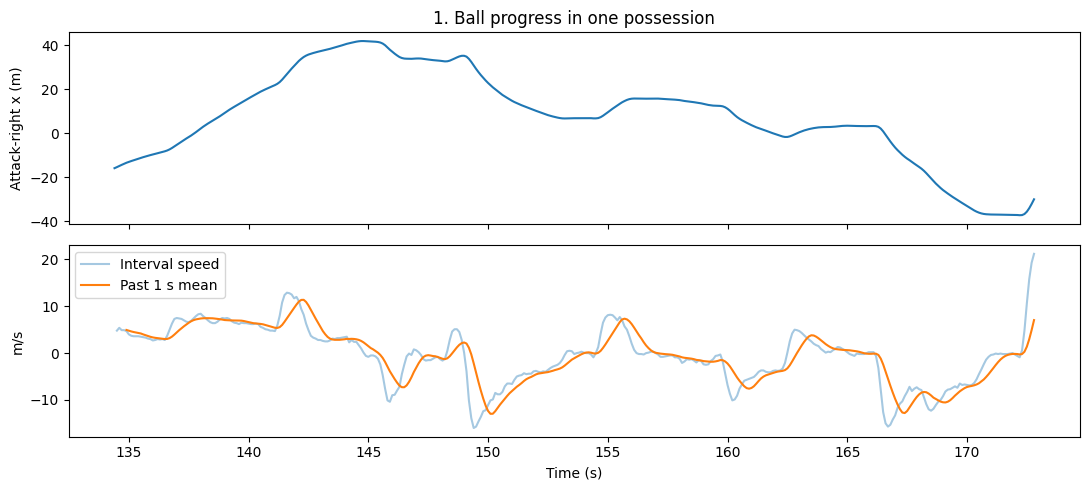

In [6]:
segment_id=frame.groupby('possession_segment').size().idxmax()
diagnostic=progression_diagnostics(frame[frame.possession_segment.eq(segment_id)])
display(diagnostic[['seconds','attack_x','dx','dt','instant_speed','past_mean']].head(12))
fig,axs=plt.subplots(2,1,figsize=(11,5),sharex=True)
axs[0].plot(diagnostic.seconds,diagnostic.attack_x)
axs[0].set(title='1. Ball progress in one possession',ylabel='Attack-right x (m)')
axs[1].plot(diagnostic.seconds,diagnostic.instant_speed,alpha=.4,label='Interval speed')
axs[1].plot(diagnostic.seconds,diagnostic.past_mean,label='Past 1 s mean')
axs[1].set(xlabel='Time (s)',ylabel='m/s')
axs[1].legend()
plt.tight_layout()
plt.show()

## A transparent rule-based state classifier
Rules below are deliberately simple: a fast early advance is a transition candidate; otherwise classify by field zone. Values are teaching choices, not SkillCorner's production definitions. Invalid ball position or unknown possession yields an unknown state.

#### Helper: `rule_phase`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [7]:
def rule_phase(row):
    if pd.isna(row.attack_x) or row.ball_owning_team_id not in [1802,871]:return 'unknown'
    if row.possession_age<8 and row.progress_1s>3:return 'transition candidate'
    if row.attack_x<-17.5:return 'deep circulation'
    if row.attack_x<17.5:return 'middle progression'
    return 'advanced possession'

In [8]:
frame['raw_phase']=frame.apply(rule_phase,axis=1)

#### Helper: `smooth_states`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def smooth_states(g):
    current='unknown';pending=None;n=0;output=[]
    for label in g.raw_phase:
        n=n+1 if label==pending else 1;pending=label
        if n>=3:current=label
        output.append(current)
    return pd.Series(output,index=g.index)

In [10]:
frame['phase']=pd.concat([smooth_states(g) for _,g in frame.groupby('possession_segment')]).sort_index()
breaks=frame.phase.ne(frame.phase.shift())|new
intervals=frame.groupby(breaks.cumsum()).agg(period=('period_id','first'),start=('seconds','min'),end=('seconds','max'),phase=('phase','first'),n=('frame_id','size'))
intervals['duration_s']=intervals.end-intervals.start+.1
display(intervals.head(12))

,period,start,end,phase,n,duration_s
1,1,3.0,3.1,unknown,2,0.2
2,1,3.2,5.2,middle progression,21,2.1
3,1,5.3,8.5,transition candidate,33,3.3
4,1,8.6,10.8,advanced possession,23,2.3
5,1,10.9,11.1,transition candidate,3,0.3
6,1,11.2,14.5,advanced possession,34,3.4
7,1,14.6,29.6,middle progression,151,15.1
8,1,29.7,29.8,unknown,2,0.2
9,1,29.9,30.3,middle progression,5,0.5
10,1,30.4,33.7,transition candidate,34,3.4


### Intermediate steps: Visualize individual rule gates and confirmation delay

Inspect rule decisions separately from persistence. Smoothing changes boundaries and adds delay; it cannot repair an unsuitable phase taxonomy.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `phase_rule_gates`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [11]:
def phase_rule_gates(frames):
    return pd.DataFrame({'early_possession':frames.possession_age.lt(8),'fast_progress':frames.progress_1s.gt(3),'deep_zone':frames.attack_x.lt(-17.5),'advanced_zone':frames.attack_x.ge(17.5)},index=frames.index)

,seconds,raw_phase,phase,early_possession,fast_progress,deep_zone,advanced_zone
0,3.0,middle progression,unknown,True,False,False,False
1,3.1,middle progression,unknown,True,False,False,False
2,3.2,middle progression,middle progression,True,False,False,False
3,3.3,middle progression,middle progression,True,False,False,False
4,3.4,middle progression,middle progression,True,False,False,False
5,3.5,middle progression,middle progression,True,False,False,False
6,3.6,middle progression,middle progression,True,False,False,False
7,3.7,middle progression,middle progression,True,False,False,False
8,3.8,middle progression,middle progression,True,False,False,False
9,3.9,middle progression,middle progression,True,False,False,False


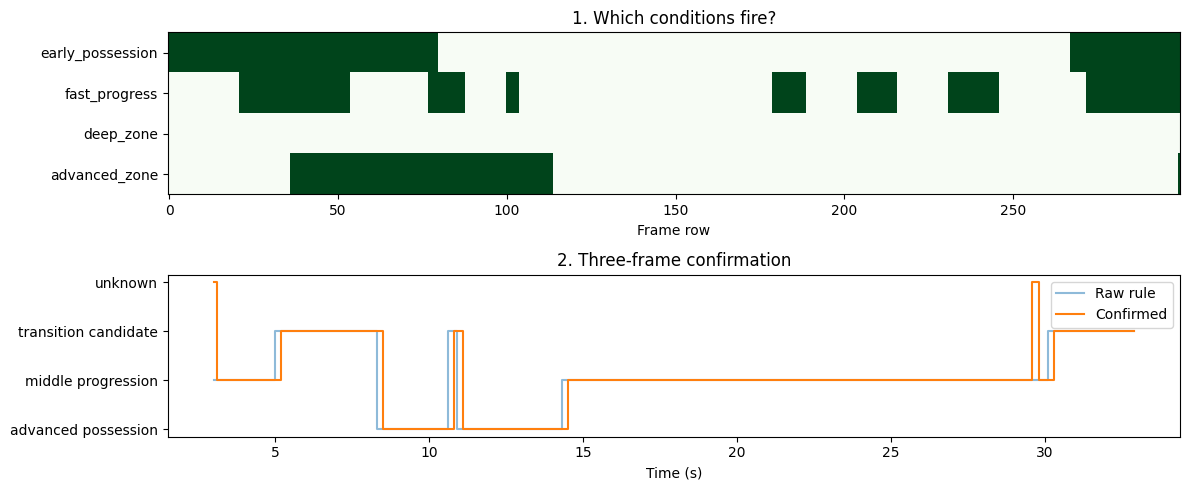

In [12]:
sample=frame.head(300)
gates=phase_rule_gates(sample)
display(pd.concat([sample[['seconds','raw_phase','phase']],gates],axis=1).head(15))
fig,axs=plt.subplots(2,1,figsize=(12,5))
axs[0].imshow(gates.to_numpy().T,aspect='auto',interpolation='nearest',cmap='Greens')
axs[0].set(yticks=range(4),yticklabels=gates.columns,title='1. Which conditions fire?',xlabel='Frame row')
labels=sorted(set(sample.raw_phase)|set(sample.phase))
mapping={v:i for i,v in enumerate(labels)}
axs[1].step(sample.seconds,sample.raw_phase.map(mapping),label='Raw rule',alpha=.5)
axs[1].step(sample.seconds,sample.phase.map(mapping),label='Confirmed')
axs[1].set(yticks=range(len(labels)),yticklabels=labels,xlabel='Time (s)',title='2. Three-frame confirmation')
axs[1].legend()
plt.tight_layout()
plt.show()

## Interval join to provider phases
Keep period and inclusive frame boundaries. Inspect overlaps rather than silently selecting one phase. Our rule taxonomy differs from the provider taxonomy, so a diagonal confusion-matrix interpretation would be misleading without a reviewed mapping.

provider_matches
1    5103
0    1015
2      35
Name: frames, dtype: int64

provider_phase,build_up,chaotic,create,direct,finish,quick_break,set_play,transition
phase,,,,,,,,
advanced possession,0,32,13,44,840,75,38,56
deep circulation,726,121,244,45,0,0,0,12
middle progression,1,20,1675,128,280,0,0,50
transition candidate,50,74,160,88,180,21,0,94
unknown,8,14,20,2,16,4,3,4


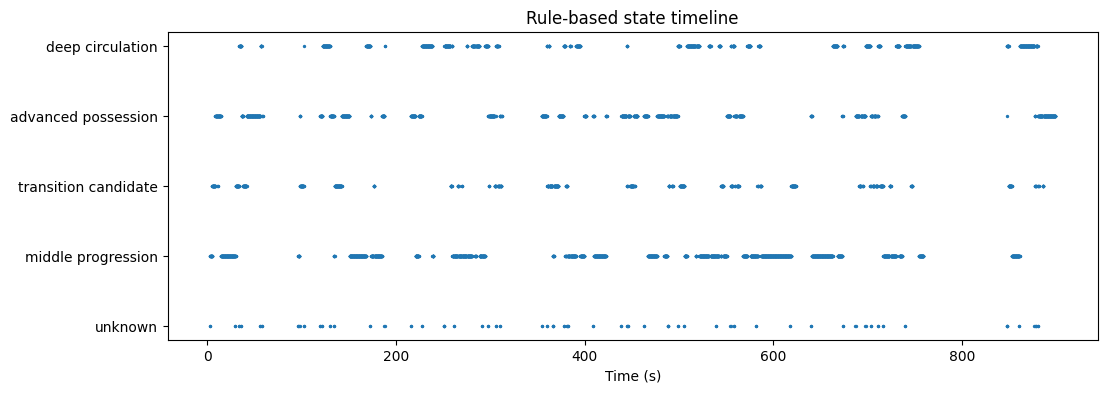

In [13]:
frame['provider_phase']=None
frame['provider_matches']=0
for r in phases.itertuples():
    mask=frame.period_id.eq(r.period)&frame.frame_id.between(r.frame_start,r.frame_end)&frame.ball_owning_team_id.eq(r.team_in_possession_id)
    frame.loc[mask,'provider_matches']+=1
    frame.loc[mask,'provider_phase']=r.team_in_possession_phase_type
display(frame.provider_matches.value_counts().rename('frames'))
display(pd.crosstab(frame.phase,frame.provider_phase))
fig,ax=plt.subplots(figsize=(12,4))
labels=list(frame.phase.unique())
mapping={v:i for i,v in enumerate(labels)}
ax.scatter(frame.seconds,frame.phase.map(mapping),s=2)
ax.set(yticks=range(len(labels)),yticklabels=labels,xlabel='Time (s)',title='Rule-based state timeline')
plt.show()

**Next step:** learn a classifier or a sequence model on reviewed phases, using match-level splits and boundary-tolerant evaluation. Hysteresis reduces flicker but introduces detection delay. Possession changes, dead-ball states and camera gaps need explicit treatment. [SkillCorner data and labels](https://github.com/SkillCorner/opendata).

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
